In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Input,Dense,Lambda
from tensorflow.keras.models import Model
from tensorflow.keras.datasets import mnist

In [5]:
(x_train, _), (x_test, _) = mnist.load_data()

x_train = x_train.astype("float32").reshape(-1, 784) / 255.0
x_test = x_test.astype("float32").reshape(-1, 784) / 255.0

# Use a smaller training set to make training faster
x_train = x_train[:10000]

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (10000, 784)
Testing shape: (10000, 784)


In [6]:
latent_dim=2
inputs=Input(shape=(784,))
h=Dense(128,activation="relu")(inputs)
mu=Dense(latent_dim,name="mu")(h)
log_var=Dense(latent_dim,name="log_var")(h)
def sampling(args):
    mu,log_var=args
    epsilon=tf.random.normal(shape=tf.shape(mu))
    return mu+tf.exp(0.5*log_var)*epsilon
z=Lambda(sampling,name="sampling")([mu,log_var])
encoder=Model(inputs,[mu,log_var,z],name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 784)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │         100,480 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ mu (Dense)                    │ (None, 2)                 │             258 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ log_var (Dense)               │ (None, 2)                 │             258 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sampling (Lambda)             │ (None, 2)                 │               0 │ mu[0][0], log_var[0][0]    │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 100,996 (394.52 KB)

 Trainable params: 100,996 (394.52 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
decoder_input=Input(shape=(latent_dim,))
h=Dense(128,activation="relu")(decoder_input)
decoder_output=Dense(784,activation="sigmoid")(h)
decoder=Model(decoder_input,decoder_output,name="decoder")
decoder.summary()


Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 2)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,520 (396.56 KB)

 Trainable params: 101,520 (396.56 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
optimizer = tf.keras.optimizers.Adam()

epochs = 20
batch_size = 256

In [20]:
for epoch in range(epochs):
    total_loss = 0.0
    batches = 0

    for start in range(0, len(x_train), batch_size):
        batch = tf.convert_to_tensor(
            x_train[start:start + batch_size]
        )

        with tf.GradientTape() as tape:
            mu_b, log_var_b, z_b = encoder(batch, training=True)

            reconstructed = decoder(z_b, training=True)

            bce = tf.keras.backend.binary_crossentropy(
                batch, reconstructed
            )

            reconstruction_loss = tf.reduce_sum(bce, axis=1)

            kl_loss = -0.5 * tf.reduce_sum(
                1 + log_var_b - tf.square(mu_b) - tf.exp(log_var_b),
                axis=1
            )

            loss = tf.reduce_mean(reconstruction_loss + kl_loss)

        variables = encoder.trainable_variables + decoder.trainable_variables
        gradients = tape.gradient(loss, variables)
        optimizer.apply_gradients(zip(gradients, variables))

        total_loss += float(loss)
        batches += 1

    print("Epoch", epoch + 1, "Loss:", round(total_loss / batches, 2))

Epoch 1 Loss: 173.25
Epoch 2 Loss: 172.61
Epoch 3 Loss: 172.14
Epoch 4 Loss: 171.73
Epoch 5 Loss: 171.43
Epoch 6 Loss: 170.99
Epoch 7 Loss: 170.67
Epoch 8 Loss: 170.37
Epoch 9 Loss: 170.08
Epoch 10 Loss: 169.73
Epoch 11 Loss: 169.46
Epoch 12 Loss: 169.23
Epoch 13 Loss: 168.98
Epoch 14 Loss: 168.76
Epoch 15 Loss: 168.53
Epoch 16 Loss: 168.38
Epoch 17 Loss: 168.22
Epoch 18 Loss: 167.95
Epoch 19 Loss: 167.7
Epoch 20 Loss: 167.59


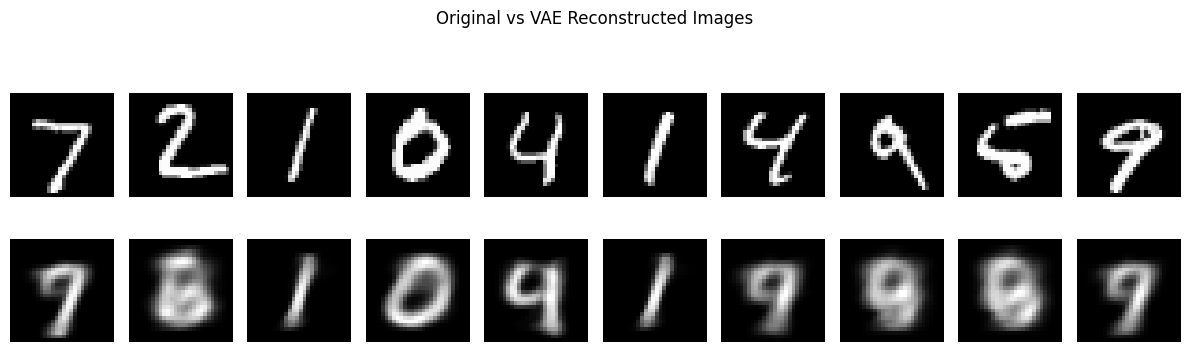

In [21]:
mu_test, _, _ = encoder(x_test[:10], training=False)

reconstructed = decoder(mu_test, training=False).numpy()

plt.figure(figsize=(12, 4))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Original vs VAE Reconstructed Images")
plt.tight_layout()
plt.show()